# Rate-limited turns: practical timestep stability

**Question.** With the maximum social turn limited to 14 rad/s, are equal-duration social simulations sufficiently stable when the internal timestep is halved at speeds 1, 3, and 5 BL/s?

**Hypothesis B.** A turn capacity expressed per physical second may make timestep refinement more interpretable. This does not guarantee practical stability: sharp interaction-zone changes, synchronous discrete decisions, and reflections can still make runs sensitive. A more cohesive school is not by itself evidence of numerical stability.

The [shared model](../../shiner_model.py) already provides `max_turn_rate`. Notebook 02 checks its implementation; this notebook tests population behaviour. No new social rule or light field is introduced. `None` remains the backwards-compatible instantaneous-turn default.

Puckett et al. (2018) report **1.75 rad per reference update**, at 0.125 s per update. Dividing these values gives **14 rad/s**. Holding that derived rate fixed as `dt` changes is our implementation convention, not a separately fitted biological parameter. The cap applies to the social turn before motion. Instantaneous wall reflection remains a separate boundary response.

In [1]:
from pathlib import Path
import sys

MODEL_DIR = next(
    folder for parent in (Path.cwd(), *Path.cwd().parents)
    for folder in (parent, parent / "papers")
    if (folder / "shiner_model.py").is_file() and (folder / "handlings").is_dir()
)
if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))
HERE = MODEL_DIR / "handlings" / "trial_three"
PAPERS = MODEL_DIR

import hashlib
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown


from handlings.trial_two.study_support import run_streamed
from handlings.trial_three.temporal_support import (
    compare_adjacent, group_aggregate, protocol_candidates,
)

DATA = HERE / "data"
FIGURES = HERE / "figures"
DATA.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
criteria = json.loads((DATA / "predeclared_criteria.json").read_text())
SEEDS = criteria["Seeds"]
SPEEDS = [1.0, 3.0, 5.0]
DTS = [0.0625, 0.03125, 0.015625, 0.0078125]
DURATION = criteria["Duration_s"]
RECORD_INTERVAL = criteria["RecordingInterval_s"]
TURN_RATE = 14.0
assert criteria["DeclaredBeforeExperiments"] is True
assert hashlib.sha256((PAPERS / "shiner_model.py").read_bytes()).hexdigest() == criteria["ModelSHA256"]
print(f"Predeclared design: {len(SEEDS)} seeds × {len(SPEEDS)} speeds × {len(DTS)} timesteps = 120 runs.")
print(f"Each run: {DURATION:g} s, output every {RECORD_INTERVAL:g} s; final {criteria['LateWindow_s']:g} s for late metrics.")
display(pd.DataFrame({"dt (s)": DTS, "maximum social turn/update (rad)": [TURN_RATE * dt for dt in DTS],
                      "internal updates/run": [round(DURATION / dt) for dt in DTS],
                      "output stride": [round(RECORD_INTERVAL / dt) for dt in DTS]}))
from handlings.trial_one.relocation import executed_source_hashes


Predeclared design: 10 seeds × 3 speeds × 4 timesteps = 120 runs.
Each run: 31.25 s, output every 0.125 s; final 12.5 s for late metrics.


,dt (s),maximum social turn/update (rad),internal updates/run,output stride
0,0.062500,0.875000,500,2
1,0.031250,0.437500,1000,4
2,0.015625,0.218750,2000,8
3,0.007812,0.109375,4000,16


## Controls and the decision declared before results

All arms use the same ten seeds, 20 fish, 20 × 20 BL reflecting arena, radii 0.5 / 3.0 / 5.5 BL, 360° perception, no angular noise, and synchronous `decide`/`advance`. The only treatment within this notebook is the internal `dt`; speed is a controlled stratum. The seed makes the initial positions/headings identical across arms. Equal update counts would give unequal physical durations and are not used.

Group outputs are saved every 0.125 s. Connectivity, assembly episodes, exact sampled overlaps, minimum pair distances, and missed repulsion-zone passages are monitored **at every internal update**, independent of recording. Polarization, rotation, nearest-neighbour distance, centroid distance, and LargestGroupFraction use the common late output grid over the last 12.5 s. ConnectedTimeFraction covers the full simulation at internal resolution.

Primary decisions use changes in the **matched-cohort ensemble means**, against the finer timestep: absolute change ≤0.05 for polarization, rotation, LargestGroupFraction, and ConnectedTimeFraction; relative change ≤10% for nearest-neighbour and centroid distances. Near-zero relative denominators have a predeclared absolute fallback. Mean missed repulsion passages must be ≤0.01 per model-second in both arms, and sampled exact overlaps must total zero. The monotonicity of rare-event rates is reported separately. These project conventions are neither biological constants nor formal convergence tests.

A candidate must pass at **all three speeds and every available finer adjacent comparison**. The finest timestep cannot qualify alone because no finer reference was run. Raw paired-seed absolute differences remain visible as sensitivity diagnostics; trajectory identity is not required for a nonlinear collective system. Ten seeds and 31.25 s provide a finite diagnostic cohort, not a long-term assembly validation.

The complete decision file was written before experiments. It is displayed below unchanged.

In [2]:
display(pd.DataFrame(criteria["MetricRules"]).T)
print("Missed-pass limit:", criteria["MaximumMissedRepulsionPassesPerSecond"], "per model-second")
print("Selection rule:", criteria["SelectionRule"])
print("Primary comparison:", criteria["PrimaryDecision"])

,kind,tolerance
Polarization,absolute,0.05
Rotation,absolute,0.05
LargestGroupFraction,absolute,0.05
ConnectedTimeFraction,absolute,0.05
MeanNND,relative,0.1
MeanDistanceToCentroid,relative,0.1


Missed-pass limit: 0.01 per model-second
Selection rule: Only select a candidate if its adjacent comparison and every finer available comparison pass at all three speeds. Prefer bounded turning if both formulations qualify, for explicit physical turn capacity, not greater cohesion.
Primary comparison: Changes in matched-cohort ensemble means at adjacent dt values; paired-seed absolute changes are reported as sensitivity diagnostics, not trajectory-identity requirements.


## Execute the matched cohort

This cell executes new cases and saves observations after each ten-case block. On a later Run All it can reuse these actual simulations only after verifying the design, source hashes, decision-file hash, and CSV hashes. An interrupted run resumes the verified completed blocks. Cached records are not synthetic results and do not count as additional scientific simulations.

In [3]:
def file_sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

source_files = [PAPERS / "shiner_model.py",
                PAPERS / "handlings/trial_two/study_support.py",
                PAPERS / "handlings/trial_one/diagnostics.py",
                HERE / "temporal_support.py", DATA / "predeclared_criteria.json"]
design = {"Seeds": SEEDS, "Speeds": SPEEDS, "Dts": DTS, "Duration_s": DURATION,
          "RecordingInterval_s": RECORD_INTERVAL, "MaxTurnRate_rad_s": TURN_RATE,
          "FOV_degrees": 360.0, "AngularNoise": 0.0,
          "SourceSHA256": executed_source_hashes(source_files, MODEL_DIR)}
summary_path = DATA / "03_case_summary.csv"
trace_path = DATA / "03_sampled_traces.csv"
manifest_path = DATA / "03_run_manifest.json"
summaries, traces = [], []
if manifest_path.exists():
    manifest = json.loads(manifest_path.read_text())
    assert manifest["Design"] == design, "Cached design/source changed; review provenance before rerunning."
    assert file_sha(summary_path) == manifest["SummarySHA256"]
    assert file_sha(trace_path) == manifest["TraceSHA256"]
    cached_summary = pd.read_csv(summary_path)
    cached_trace = pd.read_csv(trace_path)
    summaries = cached_summary.to_dict("records")
    traces = [cached_trace]
    print(f"Verified {len(summaries)} previously executed scientific cases.", flush=True)

finished = {(int(row["Seed"]), float(row["Speed"]), float(row["dt"])) for row in summaries}
assert len(finished) == len(summaries)
new_runs = 0
start = time.monotonic()
def save_cases(complete):
    pd.DataFrame(summaries).sort_values(["Speed", "dt", "Seed"]).to_csv(summary_path, index=False)
    pd.concat(traces, ignore_index=True).sort_values(["Speed", "dt", "Seed", "Time"]).to_csv(trace_path, index=False)
    manifest_path.write_text(json.dumps({"Design": design, "Complete": bool(complete),
                                       "ScientificRuns": len(summaries),
                                       "SummarySHA256": file_sha(summary_path),
                                       "TraceSHA256": file_sha(trace_path)}, indent=2) + "\n")

for dt in DTS:
    for speed in SPEEDS:
        for seed in SEEDS:
            key = (int(seed), speed, dt)
            if key in finished:
                continue
            result, trace, _ = run_streamed(seed=seed, duration=DURATION, speed=speed, dt=dt,
                                            record_interval=RECORD_INTERVAL,
                                            max_turn_rate=TURN_RATE, fov_degrees=360.0, angular_noise=0.0)
            trace = trace.assign(Seed=seed, Speed=speed, dt=dt)
            summaries.append(result)
            traces.append(trace)
            finished.add(key)
            new_runs += 1
        save_cases(complete=len(summaries) == 120)
        print(f"Completed {len(summaries)}/120 cases; speed={speed:g}, dt={dt:g}; "
              f"this execution elapsed {time.monotonic() - start:.1f} s.", flush=True)

summary = pd.read_csv(summary_path)
traces = pd.read_csv(trace_path)
assert len(summary) == 120
assert summary.groupby(["Speed", "dt"]).size().eq(10).all()
assert len(traces) == 120 * (round(DURATION / RECORD_INTERVAL) + 1)
assert np.allclose(summary.Duration_s, DURATION)
assert np.allclose(summary.RecordingInterval, RECORD_INTERVAL)
assert summary.SavedGroupRecords.eq(251).all()
assert (summary.InternalUpdates * summary.dt).eq(DURATION).all()
print(f"Cohort verified: 120 scientific cases; {new_runs} newly executed in this kernel.")
print(f"{len(traces):,} retained group records; {summary.InternalUpdates.sum():,} internal updates inspected.")

Completed 10/120 cases; speed=1, dt=0.0625; this execution elapsed 3.8 s.


Completed 20/120 cases; speed=3, dt=0.0625; this execution elapsed 7.6 s.


Completed 30/120 cases; speed=5, dt=0.0625; this execution elapsed 11.5 s.


Completed 40/120 cases; speed=1, dt=0.03125; this execution elapsed 18.9 s.


Completed 50/120 cases; speed=3, dt=0.03125; this execution elapsed 26.6 s.


Completed 60/120 cases; speed=5, dt=0.03125; this execution elapsed 34.4 s.


... (3 outputs left out)

Completed 100/120 cases; speed=1, dt=0.0078125; this execution elapsed 109.9 s.


Completed 110/120 cases; speed=3, dt=0.0078125; this execution elapsed 138.7 s.


Completed 120/120 cases; speed=5, dt=0.0078125; this execution elapsed 167.2 s.


Cohort verified: 120 scientific cases; 120 newly executed in this kernel.
30,120 retained group records; 225,000 internal updates inspected.


## Aggregate results and adjacent-timestep decisions

Each row below is a mean over the same ten seeds except the explicitly named counts and minima. AssemblySuccessRate refers to one attraction-radius connected component persisting for 5 s; AssemblyTime is the onset of that qualifying episode. At this short duration, censored runs are meaningful observations and do not establish failure to assemble eventually. The final long cohort, if justified, belongs in notebook 04.

In [4]:
aggregate = group_aggregate(summary)
decisions, metric_changes = compare_adjacent(summary, DTS)
accepted_dts = protocol_candidates(decisions, DTS)
aggregate.to_csv(DATA / "03_aggregate.csv", index=False)
decisions.to_csv(DATA / "03_adjacent_comparisons.csv", index=False)
metric_changes.to_csv(DATA / "03_metric_comparisons.csv", index=False)
display(aggregate.round(6))
display(decisions)
display(metric_changes[["Speed", "CandidateDt", "FinerDt", "Metric", "CandidateMean", "FinerMean",
                        "AbsoluteChange", "RelativeChange", "PairedMeanAbsoluteChange",
                        "PairedRelativeChange", "ToleranceKind", "Tolerance", "MetricPass"]].round(6))
print("Qualifying timesteps, coarsest first:", accepted_dts)

,Speed,dt,Seeds,Polarization,Rotation,LargestGroupFraction,ConnectedTimeFraction,MeanNND,MeanDistanceToCentroid,MissedRepulsionPassesPerSecond,TotalMissedRepulsionPasses,ExactOverlapPairs,MinimumRecordedPairDistance,MinimumMissedSeparation,AssemblySuccessRate,MeanAssemblyTime,PostAssemblyBreakupRuns
0,1.0,0.007812,10,0.885476,0.188518,0.91150,0.489375,0.577896,2.546543,0.0000,0,0,0.251782,NaN,0.7,9.630580,0
1,1.0,0.015625,10,0.921239,0.214256,0.94840,0.473400,0.634657,2.225382,0.0000,0,0,0.278621,NaN,0.7,10.129464,0
2,1.0,0.031250,10,0.921373,0.141839,0.95340,0.503300,0.576440,1.759264,0.0000,0,0,0.238829,NaN,0.8,11.617188,0
3,1.0,0.062500,10,0.788668,0.361773,0.82550,0.305800,0.671806,4.277982,0.0000,0,0,0.258474,NaN,0.4,8.187500,0
4,3.0,0.007812,10,0.987376,0.027533,1.00000,0.746350,0.527608,1.064342,0.0000,0,0,0.003803,NaN,1.0,7.933594,0
5,3.0,0.015625,10,0.978775,0.033764,0.99500,0.733300,0.530180,1.089267,0.0000,0,0,0.016421,NaN,1.0,8.348437,0
6,3.0,0.031250,10,0.950548,0.064877,0.98040,0.731000,0.535183,1.404636,0.0128,4,0,0.007682,0.498174,1.0,8.434375,0
7,3.0,0.062500,10,0.911343,0.060476,0.96435,0.675800,0.564355,1.709457,0.0480,15,0,0.005382,0.478088,1.0,10.187500,0
8,5.0,0.007812,10,0.964203,0.078250,0.97760,0.659875,0.533584,1.383269,0.0000,0,0,0.006868,NaN,1.0,10.729688,0
9,5.0,0.015625,10,0.981409,0.033994,1.00000,0.822100,0.540391,1.063108,0.0032,1,0,0.008708,0.499035,1.0,5.667188,0


,Speed,CandidateDt,FinerDt,Seeds,MetricsPass,FailedMetrics,CandidateMissedPassRate,FinerMissedPassRate,CrossingRateNonIncreasing,CrossingRatePass,ExactOverlapPass,Pass
0,1.0,0.062500,0.031250,10,False,"Polarization, Rotation, LargestGroupFraction, ...",0.0000,0.0000,True,True,True,False
1,1.0,0.031250,0.015625,10,False,"Rotation, MeanDistanceToCentroid",0.0000,0.0000,True,True,True,False
2,1.0,0.015625,0.007812,10,False,MeanDistanceToCentroid,0.0000,0.0000,True,True,True,False
3,3.0,0.062500,0.031250,10,False,"ConnectedTimeFraction, MeanDistanceToCentroid",0.0480,0.0128,True,False,True,False
4,3.0,0.031250,0.015625,10,False,MeanDistanceToCentroid,0.0128,0.0000,True,False,True,False
5,3.0,0.015625,0.007812,10,True,,0.0000,0.0000,True,True,True,True
6,5.0,0.062500,0.031250,10,True,,0.3040,0.0416,True,False,True,False
7,5.0,0.031250,0.015625,10,False,MeanDistanceToCentroid,0.0416,0.0032,True,False,True,False
8,5.0,0.015625,0.007812,10,False,"ConnectedTimeFraction, MeanDistanceToCentroid",0.0032,0.0000,True,True,True,False


,Speed,CandidateDt,FinerDt,Metric,CandidateMean,FinerMean,AbsoluteChange,RelativeChange,PairedMeanAbsoluteChange,PairedRelativeChange,ToleranceKind,Tolerance,MetricPass
0,1.0,0.062500,0.031250,Polarization,0.788668,0.921373,0.132704,0.144029,0.170391,0.184932,absolute,0.05,False
1,1.0,0.062500,0.031250,Rotation,0.361773,0.141839,0.219934,1.550593,0.286753,2.021683,absolute,0.05,False
2,1.0,0.062500,0.031250,LargestGroupFraction,0.825500,0.953400,0.127900,0.134151,0.157900,0.165618,absolute,0.05,False
3,1.0,0.062500,0.031250,ConnectedTimeFraction,0.305800,0.503300,0.197500,0.392410,0.331500,0.658653,absolute,0.05,False
4,1.0,0.062500,0.031250,MeanNND,0.671806,0.576440,0.095366,0.165440,0.150989,0.261933,relative,0.10,False
5,1.0,0.062500,0.031250,MeanDistanceToCentroid,4.277982,1.759264,2.518718,1.431689,3.104467,1.764640,relative,0.10,False
6,1.0,0.031250,0.015625,Polarization,0.921373,0.921239,0.000134,0.000146,0.021731,0.023589,absolute,0.05,True
7,1.0,0.031250,0.015625,Rotation,0.141839,0.214256,0.072417,0.337994,0.090301,0.421461,absolute,0.05,False
8,1.0,0.031250,0.015625,LargestGroupFraction,0.953400,0.948400,0.005000,0.005272,0.005000,0.005272,absolute,0.05,True
9,1.0,0.031250,0.015625,ConnectedTimeFraction,0.503300,0.473400,0.029900,0.063160,0.067200,0.141952,absolute,0.05,True


Qualifying timesteps, coarsest first: []


## Diagnostic plots

The first panel set shows raw group behaviour, rather than replacing measurements with pass/fail labels. Individual-seed nearest-neighbour curves expose hidden sensitivity or cancellation in ensemble means. The missed-pass plot addresses interactions traversed between decisions: both endpoints are outside 0.5 BL while the inferred straight relative segment enters that radius. Reflected path pairs are excluded from this diagnostic. These are missed interaction-zone observations, not proven body collisions. Sampled exact coincidence is a separate check and does not detect every continuous-time contact.

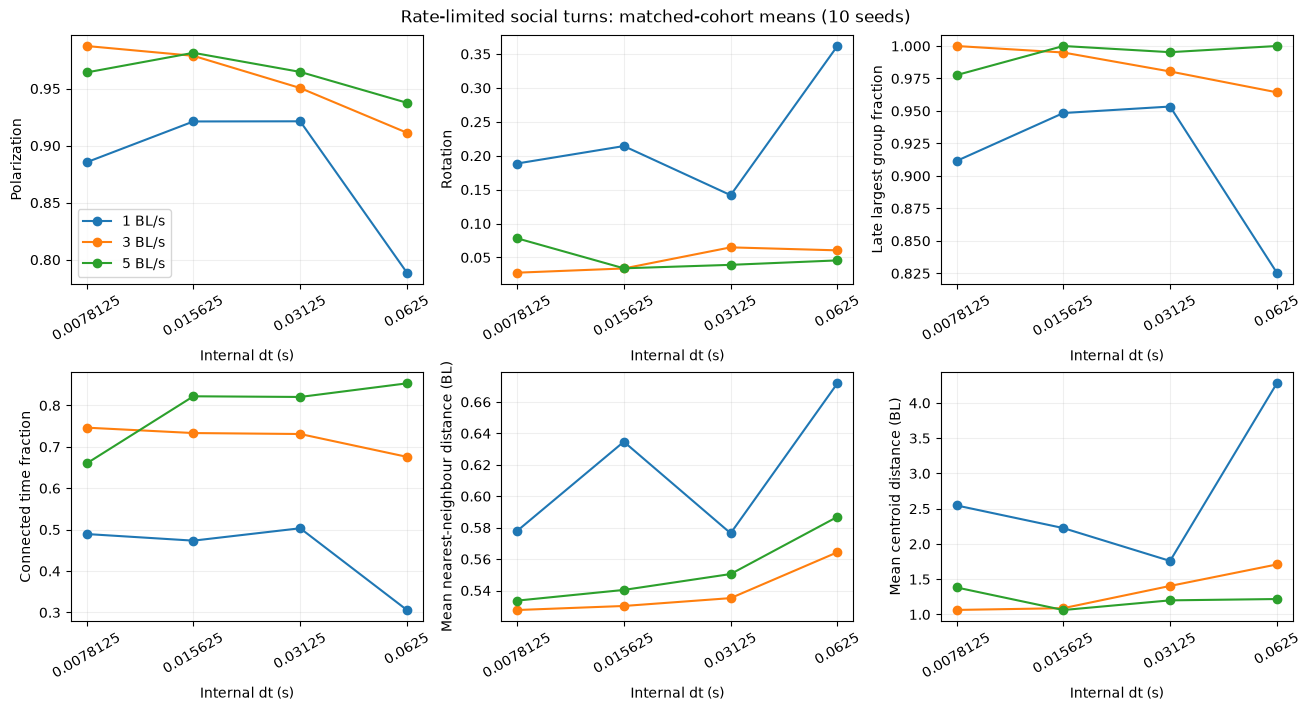

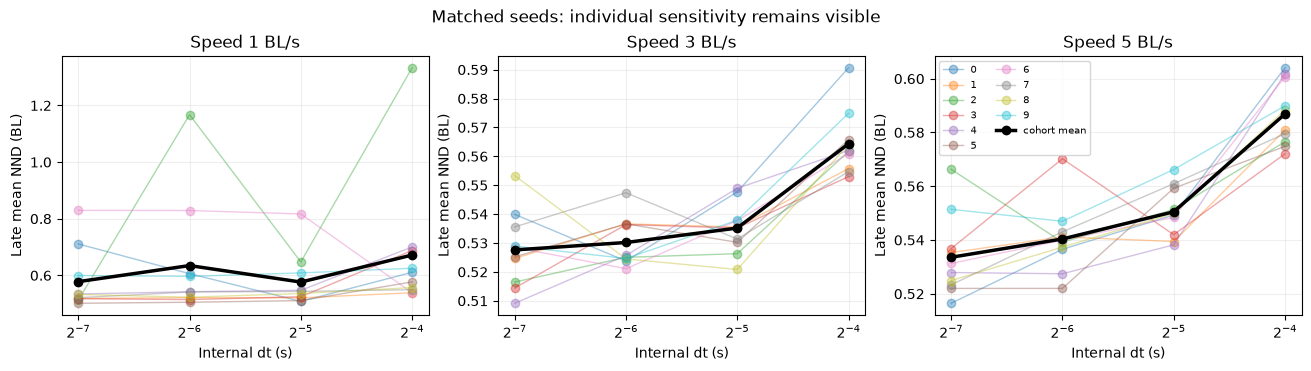

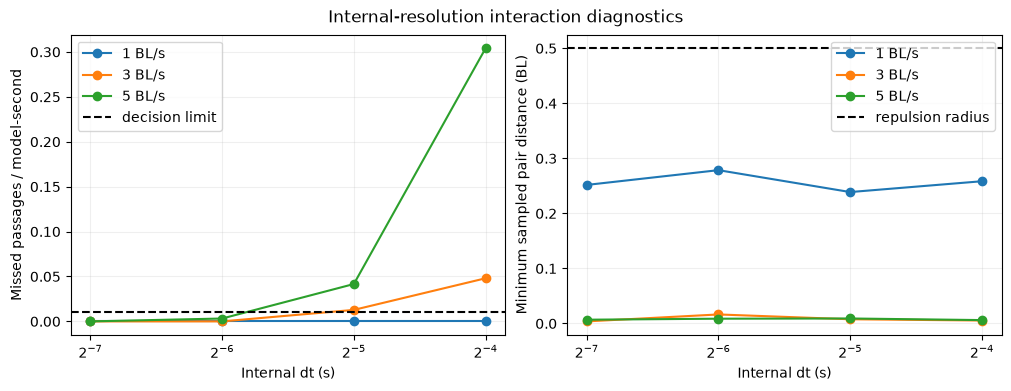

In [5]:
metrics_to_plot = [("Polarization", "Polarization"), ("Rotation", "Rotation"),
                   ("LargestGroupFraction", "Late largest group fraction"),
                   ("ConnectedTimeFraction", "Connected time fraction"),
                   ("MeanNND", "Mean nearest-neighbour distance (BL)"),
                   ("MeanDistanceToCentroid", "Mean centroid distance (BL)")]
fig, axes = plt.subplots(2, 3, figsize=(13, 7), constrained_layout=True)
for ax, (metric, label) in zip(axes.flat, metrics_to_plot):
    for speed in SPEEDS:
        rows = aggregate.loc[aggregate.Speed == speed].sort_values("dt")
        ax.plot(rows.dt, rows[metric], "o-", label=f"{speed:g} BL/s")
    ax.set_xscale("log", base=2)
    ax.set_xticks(sorted(DTS), labels=[f"{dt:g}" for dt in sorted(DTS)], rotation=30)
    ax.set_xlabel("Internal dt (s)")
    ax.set_ylabel(label)
    ax.grid(alpha=.2)
axes[0, 0].legend()
fig.suptitle("Rate-limited social turns: matched-cohort means (10 seeds)")
fig.savefig(FIGURES / "03_bounded_metric_refinement.png", dpi=160)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), constrained_layout=True)
for ax, speed in zip(axes, SPEEDS):
    rows = summary.loc[summary.Speed == speed]
    for seed, group in rows.groupby("Seed"):
        group = group.sort_values("dt")
        ax.plot(group.dt, group.MeanNND, "o-", alpha=.4, linewidth=1, label=str(seed))
    mean = aggregate.loc[aggregate.Speed == speed].sort_values("dt")
    ax.plot(mean.dt, mean.MeanNND, "ko-", linewidth=2.5, label="cohort mean")
    ax.set_xscale("log", base=2)
    ax.set_title(f"Speed {speed:g} BL/s")
    ax.set_xlabel("Internal dt (s)")
    ax.set_ylabel("Late mean NND (BL)")
    ax.grid(alpha=.2)
axes[-1].legend(fontsize=7, ncol=2)
fig.suptitle("Matched seeds: individual sensitivity remains visible")
fig.savefig(FIGURES / "03_bounded_matched_seed_nnd.png", dpi=160)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)
for speed in SPEEDS:
    rows = aggregate.loc[aggregate.Speed == speed].sort_values("dt")
    axes[0].plot(rows.dt, rows.MissedRepulsionPassesPerSecond, "o-", label=f"{speed:g} BL/s")
    axes[1].plot(rows.dt, rows.MinimumRecordedPairDistance, "o-", label=f"{speed:g} BL/s")
for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xlabel("Internal dt (s)")
    ax.grid(alpha=.2)
axes[0].axhline(criteria["MaximumMissedRepulsionPassesPerSecond"], color="black", linestyle="--", label="decision limit")
axes[0].set_ylabel("Missed passages / model-second")
axes[1].axhline(.5, color="black", linestyle="--", label="repulsion radius")
axes[1].set_ylabel("Minimum sampled pair distance (BL)")
axes[0].legend()
axes[1].legend()
fig.suptitle("Internal-resolution interaction diagnostics")
fig.savefig(FIGURES / "03_bounded_missed_passes.png", dpi=160)
plt.show()

## Compare turning formulations under the same decision rule

The common adjacent pairs are compared only after both notebooks have actually executed. The additional coarse 0.0625 s bounded arm is retained in its own decision table. Selection depends on stability across the speed range, not higher polarization, density, or assembly success alone. This is a comparison of these specific formulations and horizons, not a universal verdict on alignment models.

In [6]:
instant_path = DATA / "01_adjacent_comparisons.csv"
formulation_comparison = pd.DataFrame()
instant_candidates = None
if instant_path.exists() and (DATA / "01_case_summary.csv").exists():
    instant_decisions = pd.read_csv(instant_path)
    instant_summary = pd.read_csv(DATA / "01_case_summary.csv")
    assert len(instant_summary) == 90
    instant_candidates = protocol_candidates(instant_decisions, [0.03125, 0.015625, 0.0078125])
    bounded = decisions.assign(Formulation="bounded 14 rad/s")
    instantaneous = instant_decisions.assign(Formulation="instantaneous")
    formulation_comparison = pd.concat([instantaneous, bounded], ignore_index=True)
    formulation_comparison.to_csv(DATA / "03_formulation_comparison.csv", index=False)
    display(formulation_comparison[["Formulation", "Speed", "CandidateDt", "FinerDt", "FailedMetrics",
                                    "CandidateMissedPassRate", "FinerMissedPassRate", "Pass"]])
    print("Instantaneous candidate timesteps:", instant_candidates)
    print("Bounded candidate timesteps:", accepted_dts)
else:
    print("Notebook 01 cohort not yet available. Run this cell again after notebook 01; no comparison is inferred.")

,Formulation,Speed,CandidateDt,FinerDt,FailedMetrics,CandidateMissedPassRate,FinerMissedPassRate,Pass
0,instantaneous,1.0,0.031250,0.015625,"Polarization, ConnectedTimeFraction, MeanNND, ...",0.0000,0.0000,False
1,instantaneous,1.0,0.015625,0.007812,"ConnectedTimeFraction, MeanDistanceToCentroid",0.0000,0.0000,False
2,instantaneous,3.0,0.031250,0.015625,"MeanNND, MeanDistanceToCentroid",0.0192,0.0096,False
3,instantaneous,3.0,0.015625,0.007812,"Polarization, Rotation, ConnectedTimeFraction,...",0.0096,0.0000,False
4,instantaneous,5.0,0.031250,0.015625,ConnectedTimeFraction,0.0928,0.0160,False
5,instantaneous,5.0,0.015625,0.007812,MeanDistanceToCentroid,0.0160,0.0000,False
6,bounded 14 rad/s,1.0,0.062500,0.031250,"Polarization, Rotation, LargestGroupFraction, ...",0.0000,0.0000,False
7,bounded 14 rad/s,1.0,0.031250,0.015625,"Rotation, MeanDistanceToCentroid",0.0000,0.0000,False
8,bounded 14 rad/s,1.0,0.015625,0.007812,MeanDistanceToCentroid,0.0000,0.0000,False
9,bounded 14 rad/s,3.0,0.062500,0.031250,"ConnectedTimeFraction, MeanDistanceToCentroid",0.0480,0.0128,False


Instantaneous candidate timesteps: []
Bounded candidate timesteps: []


## Findings and their practical meaning

The conclusions below are derived from the saved raw measurements. Passing a tested adjacent pair supports a project decision within this finite matched cohort; it does not prove mathematical convergence. The assembly/checkpoint gates in notebook 04 remain necessary even if a temporal candidate qualifies here.

In [7]:
failures = []
for _, row in decisions.iterrows():
    if not row.Pass:
        failures.append({"Speed": float(row.Speed), "CandidateDt": float(row.CandidateDt),
                         "FinerDt": float(row.FinerDt), "FailedMetrics": row.FailedMetrics,
                         "CrossingRatePass": bool(row.CrossingRatePass),
                         "ExactOverlapPass": bool(row.ExactOverlapPass)})
findings = {"Formulation": "bounded social turns", "MaxTurnRate_rad_s": TURN_RATE,
            "RateInterpretation": "Derived from 1.75 rad/reference update at 0.125 s; implementation scaling convention, not fitted rate",
            "ScientificRuns": len(summary), "Seeds": SEEDS, "Speeds": SPEEDS, "Dts": DTS,
            "Duration_s": DURATION, "RecordingInterval_s": RECORD_INTERVAL,
            "AcceptedCandidateDts": accepted_dts, "AnyCandidatePasses": bool(accepted_dts),
            "ExactOverlapPairs": int(summary.ExactOverlapPairs.sum()),
            "TotalMissedRepulsionPasses": int(summary.MissedRepulsionPasses.sum()),
            "MinimumRecordedPairDistance": float(summary.MinimumRecordedPairDistance.min()),
            "RejectedComparisons": failures,
            "InstantaneousCandidates": instant_candidates,
            "ComparisonAvailable": instant_candidates is not None,
            "NoLightImplemented": True,
            "Limits": ["Ten matched seeds", "31.25-second finite horizon", "Only three tested speeds",
                       "Social turn cap excludes wall reflection", "Missed-pass geometry excludes reflected paths",
                       "No finer reference below 0.0078125 seconds", "Final assembly/checkpoint gates are separate"]}
(DATA / "03_findings.json").write_text(json.dumps(findings, indent=2, allow_nan=False) + "\n")
lines = [f"**120 bounded-turn scientific runs completed.** {int(decisions.Pass.sum())}/{len(decisions)} speed/pair decisions passed.",
         f"Sampled exact-overlap pairs across all internal updates: **{findings['ExactOverlapPairs']}**."]
if accepted_dts:
    lines.append(f"**Qualifying internal dt: {accepted_dts[0]:g} s** (coarsest accepted candidate). Every available finer adjacent comparison passes at all three speeds. This is a candidate for the separate long assembly validation, not permission to implement light.")
else:
    lines.append("**No bounded-turn timestep qualifies under the predeclared rule.** Reducing dt or adding a physical turn cap has not established the required practical stability across all tested speeds. The finest tested dt cannot be selected without a finer comparison.")
for _, row in decisions.iterrows():
    status = "PASS" if row.Pass else "FAIL"
    reasons = []
    if row.FailedMetrics:
        reasons.append(str(row.FailedMetrics))
    if not row.CrossingRatePass:
        reasons.append("missed-passage rate")
    if not row.ExactOverlapPass:
        reasons.append("exact overlaps")
    suffix = "; failed: " + ", ".join(reasons) if reasons else ""
    lines.append(f"Speed {row.Speed:g}, dt {row.CandidateDt:g} → {row.FinerDt:g}: **{status}**{suffix}; missed-passage rates {row.CandidateMissedPassRate:.5f} → {row.FinerMissedPassRate:.5f} /model/s.")
if instant_candidates is not None:
    lines.append(f"Under the same criteria, instantaneous candidate timesteps are {instant_candidates}; bounded candidate timesteps are {accepted_dts}. Compare physical interpretability separately from which metrics pass: a fixed turn rate defines a consistent social turning capacity, but successful implementation alone does not establish timestep stability.")
lines.append("The short-cohort assembly columns characterize this experiment only. They cannot replace 30 random-start runs of 180 s under an accepted final protocol. No old checkpoint is promoted to a new protocol.")
display(Markdown("\n\n".join(lines)))

**120 bounded-turn scientific runs completed.** 1/9 speed/pair decisions passed.

Sampled exact-overlap pairs across all internal updates: **0**.

**No bounded-turn timestep qualifies under the predeclared rule.** Reducing dt or adding a physical turn cap has not established the required practical stability across all tested speeds. The finest tested dt cannot be selected without a finer comparison.

Speed 1, dt 0.0625 → 0.03125: **FAIL**; failed: Polarization, Rotation, LargestGroupFraction, ConnectedTimeFraction, MeanNND, MeanDistanceToCentroid; missed-passage rates 0.00000 → 0.00000 /model/s.

Speed 1, dt 0.03125 → 0.015625: **FAIL**; failed: Rotation, MeanDistanceToCentroid; missed-passage rates 0.00000 → 0.00000 /model/s.

Speed 1, dt 0.015625 → 0.0078125: **FAIL**; failed: MeanDistanceToCentroid; missed-passage rates 0.00000 → 0.00000 /model/s.

Speed 3, dt 0.0625 → 0.03125: **FAIL**; failed: ConnectedTimeFraction, MeanDistanceToCentroid, missed-passage rate; missed-passage rates 0.04800 → 0.01280 /model/s.

Speed 3, dt 0.03125 → 0.015625: **FAIL**; failed: MeanDistanceToCentroid, missed-passage rate; missed-passage rates 0.01280 → 0.00000 /model/s.

Speed 3, dt 0.015625 → 0.0078125: **PASS**; missed-passage rates 0.00000 → 0.00000 /model/s.

Speed 5, dt 0.0625 → 0.03125: **FAIL**; failed: missed-passage rate; missed-passage rates 0.30400 → 0.04160 /model/s.

Speed 5, dt 0.03125 → 0.015625: **FAIL**; failed: MeanDistanceToCentroid, missed-passage rate; missed-passage rates 0.04160 → 0.00320 /model/s.

Speed 5, dt 0.015625 → 0.0078125: **FAIL**; failed: ConnectedTimeFraction, MeanDistanceToCentroid; missed-passage rates 0.00320 → 0.00000 /model/s.

Under the same criteria, instantaneous candidate timesteps are []; bounded candidate timesteps are []. Compare physical interpretability separately from which metrics pass: a fixed turn rate defines a consistent social turning capacity, but successful implementation alone does not establish timestep stability.

The short-cohort assembly columns characterize this experiment only. They cannot replace 30 random-start runs of 180 s under an accepted final protocol. No old checkpoint is promoted to a new protocol.

The raw cases, sampled traces, source-hash manifest, aggregate table, complete metric differences, adjacent decisions, formulation comparison (when available), and machine-readable findings are saved under `data/03_*`; diagnostic figures are under `figures/03_*`. No light, environmental noise, speed modulation, or gradient metric has been implemented here.